# DL_03 — Model Training, Regularization and Reproducibility

**Owner: Palak**  
**Work package 3 of 5 — training pipeline and optimization**

## Objective

Train the primary U-Net and a compact CNN benchmark on the exact same family-held-out split. All preprocessing statistics are loaded from DL_01 and were fitted on training cases only. The test set is not used for optimization, early stopping or hyperparameter selection.

## Training design

- **Target normalization:** each velocity component is standardized using valid training pixels only.
- **Loss:** masked mean squared error. Building cells and missing cells have zero weight.
- **Optimizer:** AdamW.
- **Regularization:** weight decay, dropout, gradient clipping, validation-based learning-rate reduction and early stopping.
- **Batch size:** one complete layout per batch because native grid sizes vary and must not be resampled.
- **Reproducibility:** fixed random seed, saved training history and best validation checkpoint.

The default settings are a manageable starting point for Colab GPU execution. They can be adjusted only using the validation split; do not tune against the test metrics.

In [6]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the existing repository before importing the shared Phase 2 package.
current = Path.cwd().resolve()
candidates = [current, *current.parents]
ROOT = None
for candidate in candidates:
    if (candidate / "data" / "raw").is_dir() and (candidate / "Machine Learning Pipeline").is_dir():
        ROOT = candidate
        break
    if candidate.is_dir():
        for child in candidate.iterdir():
            if child.is_dir() and (child / "data" / "raw").is_dir() and (child / "Machine Learning Pipeline").is_dir():
                ROOT = child
                break
    if ROOT is not None:
        break
if ROOT is None:
    raise FileNotFoundError("Clone/open the existing T006 repository first; the Phase 2 folder must be added at its root.")

sys.path.insert(0, str(ROOT))
from dl_src.paths import get_project_paths
PATHS = get_project_paths(ROOT)
DL_RESULTS = PATHS["dl_results"]
FIELDS_DIR = PATHS["fields"]
FIGURES_DIR = PATHS["figures"]
MODELS_DIR = PATHS["models"]
PREDICTIONS_DIR = PATHS["predictions"]

print("Repository root:", ROOT)
print("Runtime outputs:", DL_RESULTS)


Repository root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling
Runtime outputs: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results


In [7]:
import random
import torch
from torch.utils.data import DataLoader
from dl_src.data import FlowFieldDataset
from dl_src.models import UNetVelocity, CompactCNNVelocity
from dl_src.training import train_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

from dl_src.training import get_torch_device
DEVICE = get_torch_device()
print("Training device:", DEVICE)

manifest = pd.read_csv(DL_RESULTS / "dl_case_metadata_manifest.csv")
split_manifest = pd.read_csv(DL_RESULTS / "dl_split_manifest.csv")
with open(DL_RESULTS / "normalization_stats.json", "r", encoding="utf-8") as file:
    normalization_stats = json.load(file)

train_dataset = FlowFieldDataset(manifest, split_manifest, FIELDS_DIR, "train", normalization_stats)
validation_dataset = FlowFieldDataset(manifest, split_manifest, FIELDS_DIR, "validation", normalization_stats)

train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
validation_loader = DataLoader(validation_dataset, batch_size=1, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

print("Training cases:", len(train_dataset))
print("Validation cases:", len(validation_dataset))
print("One case input shape:", tuple(train_dataset[0][0].shape))
print("One case target shape:", tuple(train_dataset[0][1].shape))
print("One case valid-mask shape:", tuple(train_dataset[0][2].shape))

Training device: mps
Training cases: 140
Validation cases: 42
One case input shape: (5, 400, 240)
One case target shape: (2, 400, 240)
One case valid-mask shape: (1, 400, 240)


## 1. Train the primary U-Net

The U-Net is the main Phase 2 model. The model predicts the two velocity components simultaneously. A base width of eight channels is used to keep the model compact enough for the small dataset and Colab GPU memory.

unet | epoch 01/25 | train=0.737279 | validation=0.641334 | lr=1.00e-03
unet | epoch 02/25 | train=0.571959 | validation=0.537832 | lr=1.00e-03
unet | epoch 03/25 | train=0.517555 | validation=0.537539 | lr=1.00e-03
unet | epoch 04/25 | train=0.487002 | validation=0.445092 | lr=1.00e-03
unet | epoch 05/25 | train=0.419972 | validation=0.390305 | lr=1.00e-03
unet | epoch 06/25 | train=0.382919 | validation=0.417214 | lr=1.00e-03
unet | epoch 07/25 | train=0.362848 | validation=0.371654 | lr=1.00e-03
unet | epoch 08/25 | train=0.329256 | validation=0.374604 | lr=1.00e-03
unet | epoch 09/25 | train=0.295258 | validation=0.374507 | lr=1.00e-03
unet | epoch 10/25 | train=0.282961 | validation=0.390487 | lr=1.00e-03
unet | epoch 11/25 | train=0.264764 | validation=0.312169 | lr=1.00e-03
unet | epoch 12/25 | train=0.238822 | validation=0.332158 | lr=1.00e-03
unet | epoch 13/25 | train=0.235713 | validation=0.293836 | lr=1.00e-03
unet | epoch 14/25 | train=0.218659 | validation=0.315971 | lr=1

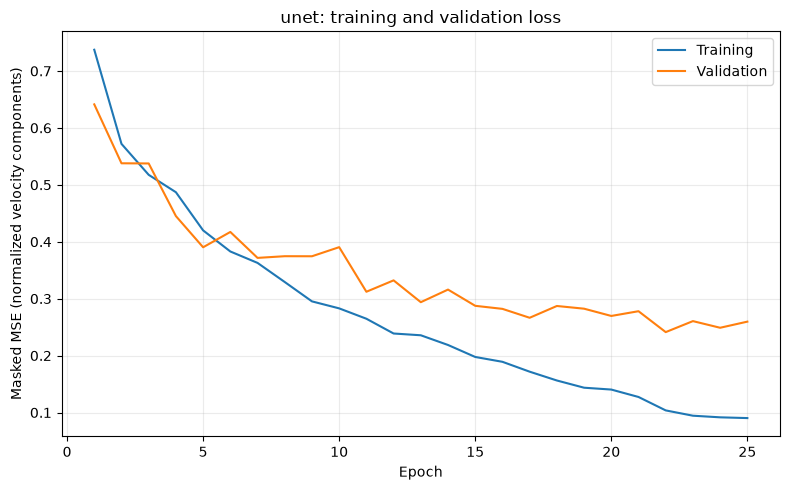

Best epoch: 22; best validation loss: 0.241263
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/unet_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/unet_training_history.csv


,epoch,train_masked_mse,validation_masked_mse,learning_rate
20,21,0.127325,0.277978,0.0005
21,22,0.103739,0.241263,0.0005
22,23,0.094422,0.260587,0.0005
23,24,0.091572,0.248910,0.0005
24,25,0.090255,0.259659,0.0005


Best U-Net checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/unet_best.pt


In [3]:
UNET_CONFIG = {
    "in_channels": 5,
    "out_channels": 2,
    "base_channels": 8,
    "dropout": 0.10,
}

unet_model = UNetVelocity(**UNET_CONFIG)
unet_model, unet_history, unet_checkpoint = train_model(
    model=unet_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    device=DEVICE,
    output_dir=DL_RESULTS,
    model_name="unet",
    epochs=25,
    learning_rate=1e-3,
    weight_decay=1e-4,
    patience=7,
    gradient_clip=1.0,
    model_config=UNET_CONFIG,
)

display(unet_history.tail())
print("Best U-Net checkpoint:", unet_checkpoint)

## 2. Train the compact CNN benchmark

This is a simpler same-resolution CNN with dilated residual blocks. It has no U-Net pooling/upsampling path or encoder-decoder skip connections. The comparison helps justify the chosen architecture rather than assuming U-Net must be better.

cnn_baseline | epoch 01/15 | train=0.653867 | validation=0.550512 | lr=1.00e-03
cnn_baseline | epoch 02/15 | train=0.548120 | validation=0.547480 | lr=1.00e-03
cnn_baseline | epoch 03/15 | train=0.527199 | validation=0.553225 | lr=1.00e-03
cnn_baseline | epoch 04/15 | train=0.500574 | validation=0.571256 | lr=1.00e-03
cnn_baseline | epoch 05/15 | train=0.506048 | validation=0.569208 | lr=1.00e-03
cnn_baseline | epoch 06/15 | train=0.499190 | validation=0.551460 | lr=5.00e-04
cnn_baseline | epoch 07/15 | train=0.482118 | validation=0.529393 | lr=5.00e-04
cnn_baseline | epoch 08/15 | train=0.466858 | validation=0.517059 | lr=5.00e-04
cnn_baseline | epoch 09/15 | train=0.460643 | validation=0.528174 | lr=5.00e-04
cnn_baseline | epoch 10/15 | train=0.461192 | validation=0.525460 | lr=5.00e-04
cnn_baseline | epoch 11/15 | train=0.454212 | validation=0.569362 | lr=5.00e-04
cnn_baseline | epoch 12/15 | train=0.451315 | validation=0.532029 | lr=2.50e-04
cnn_baseline | epoch 13/15 | train=0.442

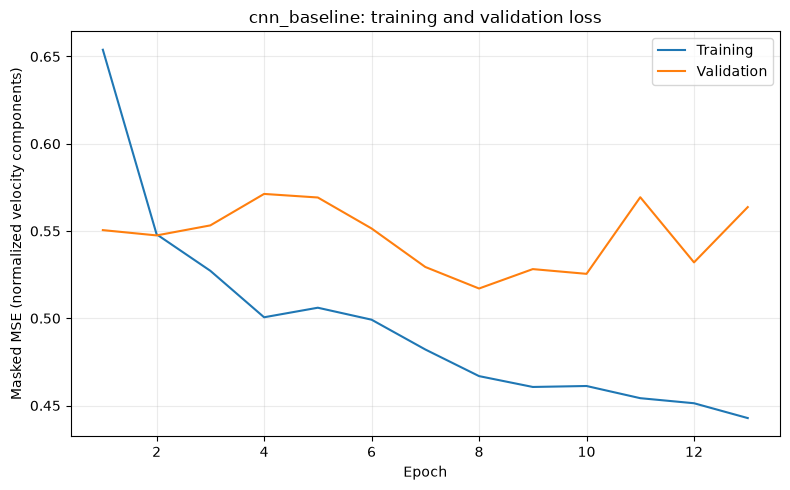

Best epoch: 8; best validation loss: 0.517059
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/cnn_baseline_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/cnn_baseline_training_history.csv


,epoch,train_masked_mse,validation_masked_mse,learning_rate
8,9,0.460643,0.528174,0.00050
9,10,0.461192,0.525460,0.00050
10,11,0.454212,0.569362,0.00050
11,12,0.451315,0.532029,0.00025
12,13,0.442811,0.563709,0.00025


CNN checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/cnn_baseline_best.pt


In [4]:
TRAIN_CNN_BASELINE = True

if TRAIN_CNN_BASELINE:
    CNN_CONFIG = {
        "in_channels": 5,
        "out_channels": 2,
        "hidden_channels": 24,
        "dropout": 0.05,
    }
    cnn_model = CompactCNNVelocity(**CNN_CONFIG)
    cnn_model, cnn_history, cnn_checkpoint = train_model(
        model=cnn_model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=DEVICE,
        output_dir=DL_RESULTS,
        model_name="cnn_baseline",
        epochs=15,
        learning_rate=1e-3,
        weight_decay=1e-4,
        patience=5,
        gradient_clip=1.0,
        model_config=CNN_CONFIG,
    )
    display(cnn_history.tail())
    print("CNN checkpoint:", cnn_checkpoint)
else:
    print("CNN baseline training skipped by configuration.")

## 3. Save the training configuration

This file records the settings used for the run. The saved training histories and checkpoints are generated only when the notebook is executed.

In [5]:
training_configuration = {
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": 1,
    "primary_model": "U-Net",
    "unet_config": UNET_CONFIG,
    "unet_max_epochs": 25,
    "cnn_baseline_trained": bool(TRAIN_CNN_BASELINE),
    "cnn_baseline_max_epochs": 15 if TRAIN_CNN_BASELINE else None,
    "optimizer": "AdamW",
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "early_stopping_patience_unet": 7,
    "early_stopping_patience_cnn": 5,
    "loss": "masked MSE over valid air cells",
    "split_file": "dl_results/dl_split_manifest.csv",
}
with open(DL_RESULTS / "training_configuration.json", "w", encoding="utf-8") as file:
    json.dump(training_configuration, file, indent=2)
print(json.dumps(training_configuration, indent=2))

{
  "seed": 42,
  "device": "mps",
  "batch_size": 1,
  "primary_model": "U-Net",
  "unet_config": {
    "in_channels": 5,
    "out_channels": 2,
    "base_channels": 8,
    "dropout": 0.1
  },
  "unet_max_epochs": 25,
  "cnn_baseline_trained": true,
  "cnn_baseline_max_epochs": 15,
  "optimizer": "AdamW",
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "gradient_clip_norm": 1.0,
  "early_stopping_patience_unet": 7,
  "early_stopping_patience_cnn": 5,
  "loss": "masked MSE over valid air cells",
  "split_file": "dl_results/dl_split_manifest.csv"
}


## 4. How to interpret the curves

- Training loss should generally decrease as the model fits the training layouts.
- Validation loss estimates performance on families not used for gradient updates.
- If training loss keeps falling while validation loss rises, the model is overfitting; early stopping restores the checkpoint with the best validation loss.
- The learning-rate scheduler reduces the learning rate when validation loss stops improving.
- The test set must remain untouched until DL_04.

## DL_03 completion checklist

- [ ] U-Net trained and best validation checkpoint saved.
- [ ] Training and validation histories saved.
- [ ] CNN baseline trained under the same split (unless explicitly disabled).
- [ ] Regularization and early stopping documented.
- [ ] Training configuration saved under `dl_results/`.

**Handoff:** Jashvitha performs final test evaluation, error mapping and ablation studies in DL_04.